# Data Analysis Project - Sales Data

## 1. Imports & Setup


In [142]:
# Import required libraries
import numpy as np  # Numerical computing
import pandas as pd  # Data manipulation and analysis
import matplotlib.pyplot as plt  # Plotting library
import seaborn as sns  # Statistical data visualization

## 2. Load Dataset


In [143]:
# Load the sales dataset from CSV file
df = pd.read_csv(r"D:\coding\Data analysis\Python\project\project_2\Dataset.csv")

## 3. Initial Data Exploration


In [144]:
# Display first 5 rows of the dataframe
df.head()

,order_id,order_date,ship_date,ship_mode,customer_name,segment,state,country,market,region,...,category,sub_category,product_name,sales,quantity,discount,profit,shipping_cost,order_priority,year
0,AG-2011-2040,1/1/2011,6/1/2011,Standard Class,Toby Braunhardt,Consumer,Constantine,Algeria,Africa,Africa,...,Office Supplies,Storage,"Tenex Lockers, Blue",408,2,0.0,106.140,35.46,Medium,2011
1,IN-2011-47883,1/1/2011,8/1/2011,Standard Class,Joseph Holt,Consumer,New South Wales,Australia,APAC,Oceania,...,Office Supplies,Supplies,"Acme Trimmer, High Speed",120,3,0.1,36.036,9.72,Medium,2011
2,HU-2011-1220,1/1/2011,5/1/2011,Second Class,Annie Thurman,Consumer,Budapest,Hungary,EMEA,EMEA,...,Office Supplies,Storage,"Tenex Box, Single Width",66,4,0.0,29.640,8.17,High,2011
3,IT-2011-3647632,1/1/2011,5/1/2011,Second Class,Eugene Moren,Home Office,Stockholm,Sweden,EU,North,...,Office Supplies,Paper,"Enermax Note Cards, Premium",45,3,0.5,-26.055,4.82,High,2011
4,IN-2011-47883,1/1/2011,8/1/2011,Standard Class,Joseph Holt,Consumer,New South Wales,Australia,APAC,Oceania,...,Furniture,Furnishings,"Eldon Light Bulb, Duo Pack",114,5,0.1,37.770,4.70,Medium,2011


In [145]:
# List all column names
df.columns.to_list()

['order_id',
 'order_date',
 'ship_date',
 'ship_mode',
 'customer_name',
 'segment',
 'state',
 'country',
 'market',
 'region',
 'product_id',
 'category',
 'sub_category',
 'product_name',
 'sales',
 'quantity',
 'discount',
 'profit',
 'shipping_cost',
 'order_priority',
 'year']

In [146]:
# Show dataframe info: data types, non-null counts, memory usage
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 51325 entries, 0 to 51324
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        51325 non-null  str    
 1   order_date      51325 non-null  str    
 2   ship_date       51325 non-null  str    
 3   ship_mode       51325 non-null  str    
 4   customer_name   51246 non-null  str    
 5   segment         51325 non-null  str    
 6   state           51325 non-null  str    
 7   country         51325 non-null  str    
 8   market          51325 non-null  str    
 9   region          51325 non-null  str    
 10  product_id      51325 non-null  str    
 11  category        51325 non-null  str    
 12  sub_category    51325 non-null  str    
 13  product_name    51325 non-null  str    
 14  sales           51325 non-null  str    
 15  quantity        51325 non-null  int64  
 16  discount        51325 non-null  float64
 17  profit          51311 non-null  float64
 1

In [147]:
# Display dataframe shape (rows, columns)
df.shape

(51325, 21)

## 4. Handle Duplicates


In [148]:
# Count number of duplicate rows
df.duplicated().sum()

np.int64(54)

In [149]:
# Remove duplicate records
df = df.drop_duplicates()

In [150]:
# Check shape after removing duplicates
df.shape

(51271, 21)

## 5. Handle Missing Values


In [151]:
# Count missing values per column
df.isna().sum()

order_id           0
order_date         0
ship_date          0
ship_mode          0
customer_name     79
segment            0
state              0
country            0
market             0
region             0
product_id         0
category           0
sub_category       0
product_name       0
sales              0
quantity           0
discount           0
profit            14
shipping_cost      0
order_priority     0
year               0
dtype: int64

In [152]:
# Total count of missing values in entire dataframe
df.isnull().sum().sum()

np.int64(93)

In [153]:
# Fill missing customer names with 'Unknown'
df["customer_name"] = df["customer_name"].fillna("Unknown")

In [154]:
# Fill missing profit values with median profit
df["profit"] = df["profit"].fillna(df["profit"].median())

## 6. Clean String Columns (Whitespace)


In [155]:
# Check for leading/trailing whitespace in all string/object columns
for i in df.select_dtypes(include=["object", "string"]).columns:
    print(f"{i}:", (df[i] != df[i].str.strip()).sum())

order_id: 0
order_date: 0
ship_date: 0
ship_mode: 0
customer_name: 0
segment: 0
state: 0
country: 0
market: 0
region: 0
product_id: 0
category: 0
sub_category: 0
product_name: 16
sales: 0
order_priority: 0


In [156]:
# Count rows where product_name has leading/trailing whitespace
(df["product_name"] != df["product_name"].str.strip()).sum()

np.int64(16)

In [157]:
# Strip whitespace from product_name column
df["product_name"] = df["product_name"].str.strip()

## 7. Convert Date Columns


In [158]:
# Check data types of date columns before conversion
df[["order_date", "ship_date"]].dtypes

order_date    str
ship_date     str
dtype: object

In [159]:
# Convert order_date to datetime (dayfirst=True for DD/MM/YYYY format)
df["order_date"] = pd.to_datetime(
    df["order_date"], dayfirst=True, format="mixed", errors="coerce"
)

In [160]:
# Convert ship_date to datetime (dayfirst=True for DD/MM/YYYY format)
df["ship_date"] = pd.to_datetime(
    df["ship_date"], dayfirst=True, format="mixed", errors="coerce"
)

In [161]:
# Verify date columns are now datetime type
df[["order_date", "ship_date"]].dtypes

order_date    datetime64[us]
ship_date     datetime64[us]
dtype: object

## 8. Clean Numeric Columns


In [162]:
# Check data types of numeric columns
df[["sales", "quantity", "discount", "profit", "shipping_cost", "year"]].dtypes

sales                str
quantity           int64
discount         float64
profit           float64
shipping_cost    float64
year               int64
dtype: object

In [163]:
# Find sales values containing commas (need cleaning)
df[df["sales"].str.contains(",")]["sales"]

27       1,648
43       3,029
58       2,574
83       2,479
84       2,174
         ...  
51186    1,831
51187    1,208
51263    1,264
51264    1,091
51266    1,049
Name: sales, Length: 2627, dtype: str

In [164]:
# Remove commas from sales and convert to numeric
df["sales"] = pd.to_numeric(df["sales"].str.replace(",", ""), errors="coerce")

In [165]:
# Verify sales column is now numeric type
df["sales"].dtypes

dtype('int64')

## 9. Basic Statistics & Aggregations


In [166]:
# Calculate total sales and profit (rounded to 2 decimals)
df[["sales", "profit"]].sum().to_frame("Total").round(2)

,Total
sales,12635222.00
profit,1467626.97


In [167]:
# Calculate average discount (rounded to 2 decimals)
df[["discount"]].mean().to_frame("Average").round(2)

,Average
discount,0.14


In [168]:
# Top 5 products by total sales
df.groupby("product_name")["sales"].sum().nlargest(5).reset_index()

,product_name,sales
0,"Apple Smart Phone, Full Size",86936
1,"Cisco Smart Phone, Full Size",76441
2,"Motorola Smart Phone, Full Size",73159
3,"Nokia Smart Phone, Full Size",71904
4,Canon imageCLASS 2200 Advanced Copier,61600


In [169]:
# Bottom 5 products by total profit (least profitable)
df.groupby("product_name")["profit"].sum().nsmallest(5)

product_name
Cubify CubeX 3D Printer Double Head Print   -8879.9704
Lexmark MX611dhe Monochrome Laser Printer   -4589.9730
Motorola Smart Phone, Cordless              -4447.0380
Cubify CubeX 3D Printer Triple Head Print   -3839.9904
Bevis Round Table, Adjustable Height        -3649.8940
Name: profit, dtype: float64

In [170]:
# Total sales by region
df.groupby("region")["sales"].sum()

region
Africa             783345
Canada              66932
Caribbean          323584
Central           2821740
Central Asia       752839
EMEA               805053
East               678548
North             1248121
North Asia         846991
Oceania           1098253
South             1600600
Southeast Asia     883702
West               725514
Name: sales, dtype: int64

## 10. Visualizations


### 10.1 Sales by Region (Bar Chart)


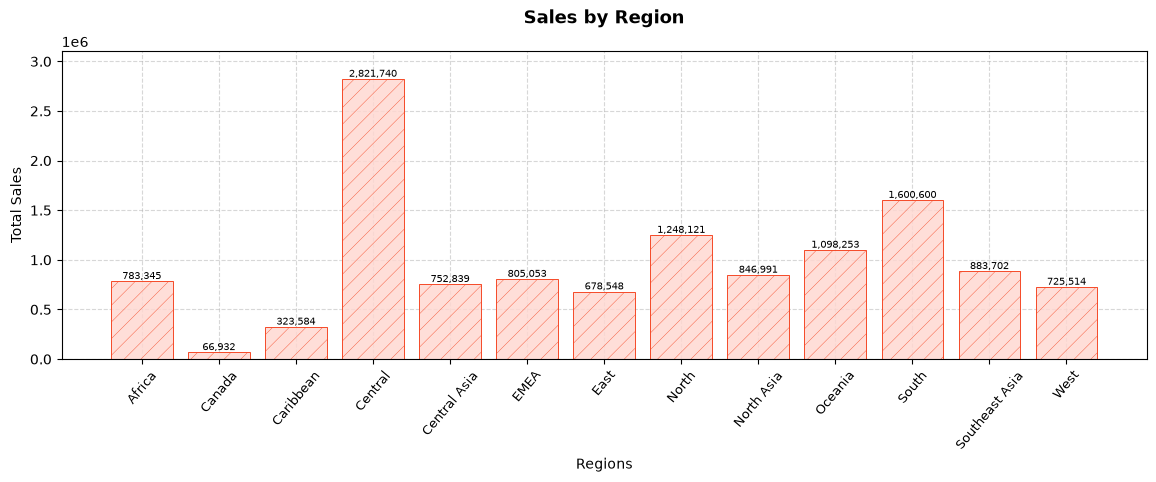

In [171]:
# Sales by Region - Bar Chart
x = df.groupby("region")["sales"].sum()

fig, ax = plt.subplots(figsize=(14, 4))
plt.rcParams["hatch.linewidth"] = 0.3
ax.bar(
    x.index,
    x.values,
    zorder=2,
    color="#FFD8D1D6",
    edgecolor="#F54927",
    linewidth=0.7,
    hatch="//",
)

ax.margins(y=0.1)
ax.set_title("Sales by Region", fontsize=13, fontweight="bold", pad=20)
ax.set_xlabel("Regions")
ax.set_ylabel("Total Sales")

# Add value labels on bars
for bar in ax.containers:
    ax.bar_label(bar, fmt="{:,.0f}", fontsize=7)

plt.xticks(rotation=50, ha="center", fontsize=9)
plt.grid(linestyle="--", alpha=0.5)
plt.savefig('sales by region.png', dpi=100, bbox_inches='tight')
plt.show()

### 10.2 Profit by Category (Pie Chart)


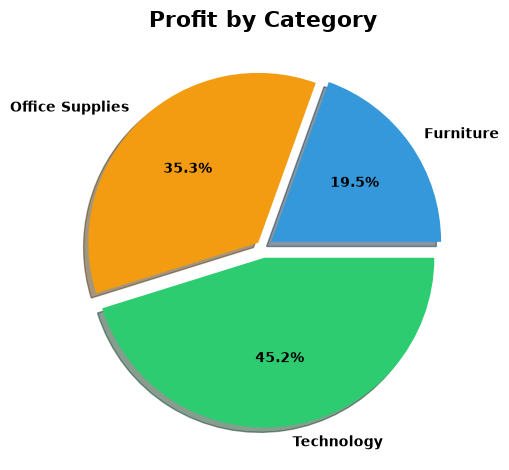

In [172]:
# Profit by Category - Pie Chart
x = df.groupby("category")["profit"].sum()
plt.pie(
    x.values,
    labels=x.index,
    autopct="%1.1f%%",  # Show percentage with 1 decimal
    shadow=True,  # Add shadow effect
    explode=(0.06, 0.04, 0.06),  # Slightly separate slices
    labeldistance=1.10,  # Distance of labels from center
    textprops={"fontsize": 10, "fontweight": "black"},
    colors=["#3498DB", "#F39C12", "#2ECC71"],
)

plt.title("Profit by Category", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.savefig('profit by category.png', dpi=100, bbox_inches='tight')
plt.show()

### 10.3 Segment-wise Sales (Bar Chart)


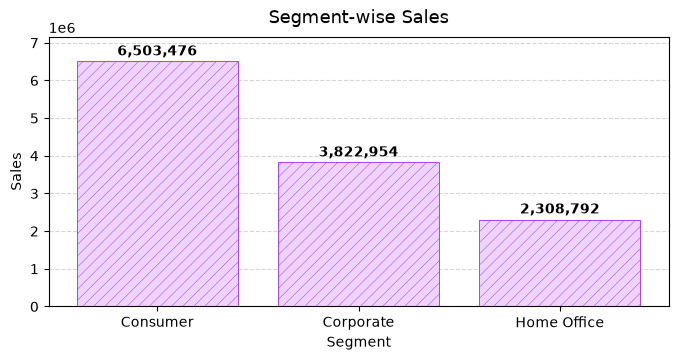

In [173]:
# Segment-wise Sales - Bar Chart
x = df.groupby("segment")["sales"].sum()
fig, ax = plt.subplots(figsize=(8, 3.5))
plt.rcParams["hatch.linewidth"] = 0.3
ax.bar(
    x.index,
    x.values,
    zorder=2,
    linewidth=0.6,
    color="#EED1FFF1",
    edgecolor="#9F27F5",
    hatch="///",
)

ax.margins(y=0.1)
ax.set_title("Segment-wise Sales", fontsize=13, pad=10)
ax.set_xlabel("Segment")
ax.set_ylabel("Sales")

# Add value labels on bars
for bar in ax.containers:
    ax.bar_label(bar, fmt="{:,.0f}", padding=2, fontweight="semibold")

plt.grid(linestyle="--", alpha=0.5, axis="y")
plt.savefig('segment-wise sales.png', dpi=100, bbox_inches='tight')
plt.show()

### 10.4 Monthly Sales Trend (Line Chart)


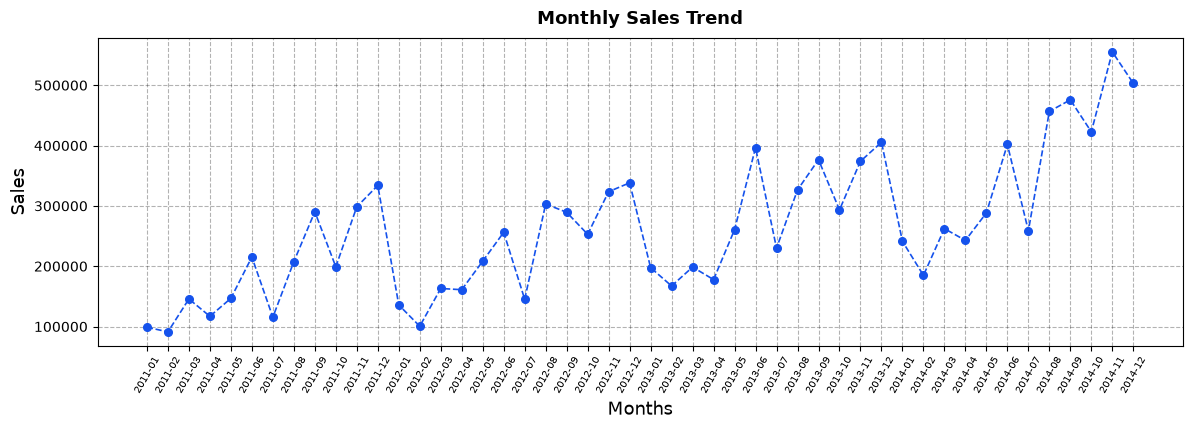

In [174]:
# Monthly Sales Trend - Line Chart
# Group by month using order_date and sum sales
x = df.groupby(df["order_date"].dt.to_period("M"))["sales"].sum()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(
    x.index.astype(str),
    x.values,
    marker="o",
    markersize=5.5,
    linewidth=1.2,
    linestyle="--",
    color="#1552EC",
)

ax.set_title("Monthly Sales Trend", fontweight="bold", fontsize=13, pad=10)
ax.set_xlabel("Months", fontsize=13)
ax.set_ylabel("Sales", fontsize=13)
plt.xticks(rotation=60, fontsize=7)
plt.grid(linestyle="--", alpha=0.3, color="black")
plt.savefig('monthly sales trend.png', dpi=100, bbox_inches='tight')
plt.show()

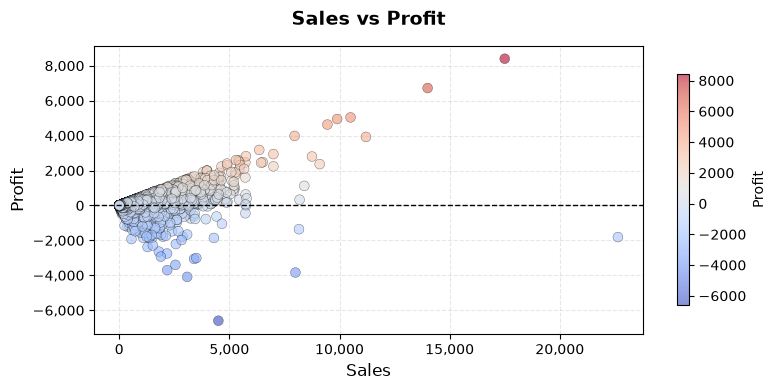

In [175]:
# Sales vs Profit Scatter Plot
import matplotlib.ticker as mticker

plt.figure(figsize=(8, 4))
scatter = plt.scatter(
    df['sales'],
    df['profit'],
    c=df['profit'],
    cmap='coolwarm',
    marker='o',
    s=50,
    alpha=0.6,
    edgecolors='#000000',
    linewidths=0.3
)
plt.colorbar(scatter, label='Profit', shrink=0.8)
plt.title('Sales vs Profit', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('Profit', fontsize=12)
plt.xlabel('Sales', fontsize=12)
plt.gca().yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
plt.gca().xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
plt.axhline(0, linestyle="--", linewidth=1, color='black')
plt.grid(linestyle='--', alpha=0.3)
plt.tight_layout()
plt.savefig('sales vs profit.png', dpi=100, bbox_inches='tight')
plt.show()

                   sales     profit  shipping_cost
category                                          
Furniture        4105771  286143.36      439684.64
Office Supplies  3786476  518237.26      405311.97
Technology       4742975  663246.35      506795.36


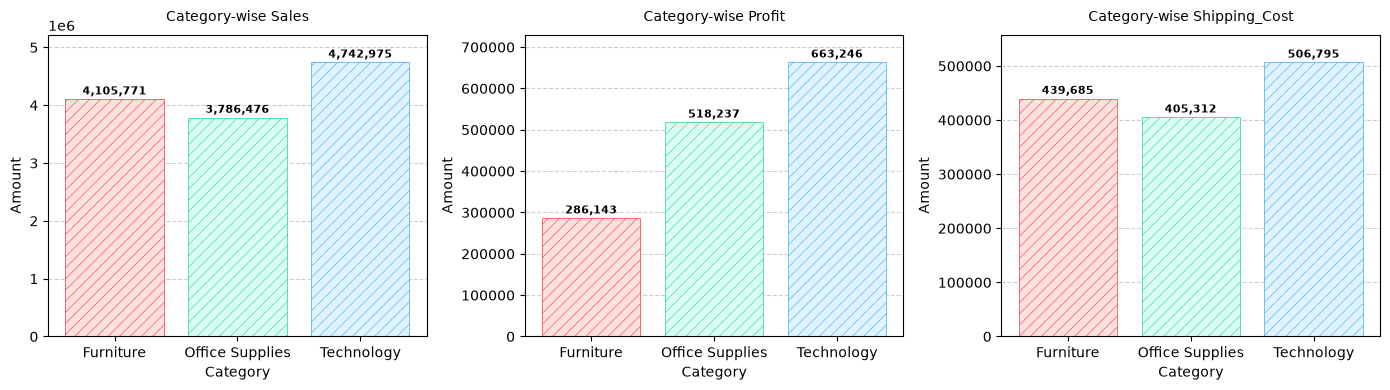

In [176]:
data = df.groupby("category")[["sales", "profit", "shipping_cost"]].sum().round(2)
print(data)

fig, ax = plt.subplots(1, 3, figsize=(14, 4))

plt.rcParams["hatch.linewidth"] = 0.4

for i, col in zip(ax, data.columns):
    bar = i.bar(
        data.index,
        data[col],
        zorder=2,
        color=["#FFE0E0", "#DAFFF2", "#E0F3FF"],
        edgecolor=["#F73636", "#21D484", "#36ADF7"],
        hatch="///",
        linewidth=0.5,
    )
    i.bar_label(bar, fmt="{:,.0f}", padding=1.5, fontweight="bold", fontsize=8)
    i.margins(y=0.1)
    i.set_title(f"Category-wise {col.title()}", fontsize=10, pad=10)
    i.set_xlabel("Category")
    i.set_ylabel("Amount")
    i.grid(linestyle="--", alpha=0.6, axis="y")

plt.tight_layout()
plt.savefig('category-wise sales profit cost.png', dpi=100, bbox_inches='tight')
plt.show()

category        Furniture  Office Supplies  Technology
region                                                
Africa             194634           266752      321959
Canada              10595            30037       26300
Caribbean          118379            89565      115640
Central            860413           922812     1038515
Central Asia       284369           162768      305702
EMEA               227604           276604      300845
East               208291           205495      264762
North              377555           374764      495802
North Asia         334367           198581      314043
Oceania            408570           281678      408005
South              515719           515240      569641
Southeast Asia     312655           241299      329748
West               252620           220881      252013


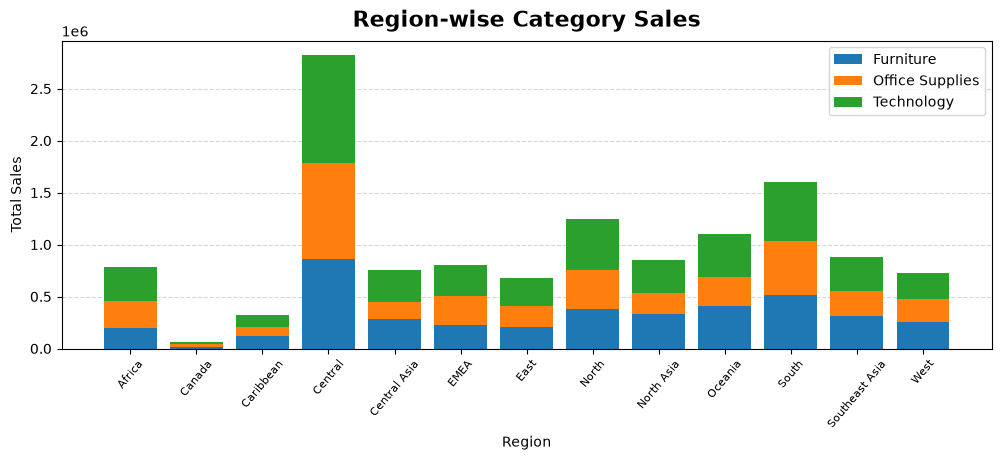

In [177]:
data = df.pivot_table(index="region", columns="category", values="sales", aggfunc="sum")
print(data)

fig, ax = plt.subplots(figsize=(12, 4))
bottom = 0

for col in data.columns:
    bar = ax.bar(data.index, data[col], bottom=bottom, label=col, zorder=2)
    bottom = bottom + data[col]

ax.legend()
ax.grid(linestyle="--", alpha=0.5, axis="y")
ax.set_title("Region-wise Category Sales", fontsize=16, fontweight="bold", pad=10)
ax.set_xlabel("Region")
ax.set_ylabel("Total Sales")
plt.xticks(rotation=50, ha="center", fontsize=8)
plt.savefig('Region-wise category sales.png', dpi=100, bbox_inches='tight')
plt.show()

C:\Users\ujjwa\AppData\Local\Temp\ipykernel_17836\2935166979.py:153: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


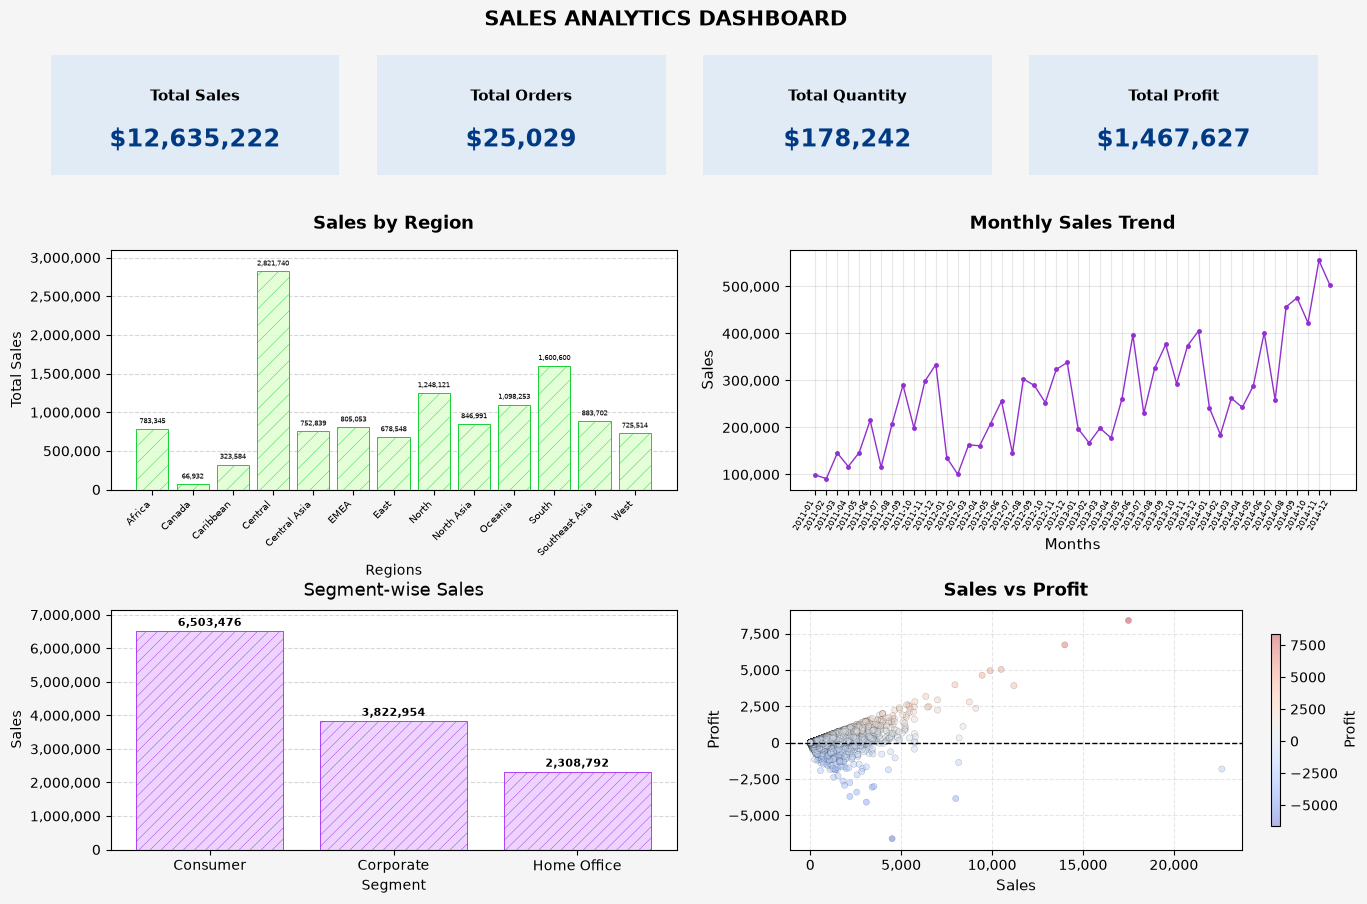

In [178]:
# Dashboard - Fixed Version
import matplotlib.ticker as mticker

# KPI Data
total_sales = df["sales"].sum()
total_order = df["order_id"].nunique()
total_quantity = df["quantity"].sum()
total_profit = df["profit"].sum()

kpis = [
    ("Total Sales", f"${total_sales:,.0f}"),
    ("Total Orders", f"${total_order:,.0f}"),
    ("Total Quantity", f"${total_quantity:,.0f}"),
    ("Total Profit", f"${total_profit:,.0f}"),
]

fig = plt.figure(figsize=(15, 10))

fig.patch.set_facecolor('#F5F5F5')
# Super title
fig.suptitle("SALES ANALYTICS DASHBOARD", fontweight="bold", fontsize=15, y=0.94)

# KPI Card Layout
left_margin = 0.09
right_margin = 0.065
gap = 0.025

card_width = (1 - left_margin - right_margin - 3 * gap) / 4

# KPI Cards
for i, (title, value) in enumerate(kpis):

    x_position = left_margin + i * (card_width + gap)
      
    ax = fig.add_axes([x_position, 0.775, card_width, 0.12])       # fig.add_axes([left, bottom, width, height])
    ax.set_facecolor("#E0EBF5")

    ax.text(0.5, 0.65, title, ha="center", va="center", fontweight="bold", fontsize=11)
    ax.text(
        0.5,
        0.29,
        value,
        ha="center",
        va="center",
        fontsize=17,
        fontweight="bold",
        color="#013A84",
    )

    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

# Chart Grid layout
gs = fig.add_gridspec(
    2, 2, 
    # Figure padding 
    left=0.13, right=0.96, top=0.70, bottom=0.10,
    # Chart Spaceing
    hspace=0.50, wspace=0.20
)

plt.rcParams["hatch.linewidth"] = 0.3

#   ---------------------------------- Charts --------------------------------------------

# Chart 1 - Sales by Region - Bar Chart
region_sales = df.groupby("region")["sales"].sum()
ax1 = fig.add_subplot(gs[0, 0])
bars = ax1.bar(
    region_sales.index,
    region_sales.values,
    zorder=2,
    color="#DFFFD1D5",
    edgecolor="#17D036",
    linewidth=0.7,
    hatch="//",
)
ax1.margins(y=0.1)
ax1.set_title("Sales by Region", fontsize=13, fontweight="bold", pad=15)
ax1.set_xlabel("Regions")
ax1.set_ylabel("Total Sales")
ax1.bar_label(bars, fmt="{:,.0f}", fontsize=5, padding=3)
plt.setp(ax1.get_xticklabels(), rotation=45, ha="right", fontsize=7)
ax1.grid(linestyle="--", alpha=0.5, axis='y')
ax1.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))

# Chart 2 - Profit by Category - Pie Chart
ax2 = fig.add_subplot(gs[1,0])
x = df.groupby("segment")["sales"].sum()
ax2.bar(
    x.index,
    x.values,
    zorder=2,
    linewidth=0.6,
    color="#EED1FFF1",
    edgecolor="#9F27F5",
    hatch="///",
)

ax2.margins(y=0.1)
ax2.set_title("Segment-wise Sales", fontsize=13, pad=10)
ax2.set_xlabel("Segment")
ax2.set_ylabel("Sales")
ax2.grid(linestyle="--", alpha=0.5, axis="y")
ax2.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
# Add value labels on bars
for bar in ax2.containers:
    ax2.bar_label(bar, fmt="{:,.0f}", padding=2, fontweight="semibold", fontsize=8)

# Chart 3 - Monthly Sales Trend - Line Chart
monthly_sales = df.groupby(df["order_date"].dt.to_period("M"))["sales"].sum()
ax3 = fig.add_subplot(gs[0, 1])
ax3.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker="o",
    markersize=2.5,
    linewidth=1,
    linestyle="-",
    color="#9230CF",
)
ax3.set_title("Monthly Sales Trend", fontweight="bold", fontsize=13, pad=15)
ax3.set_xlabel("Months", fontsize=11)
ax3.set_ylabel("Sales", fontsize=11)
plt.setp(ax3.get_xticklabels(), rotation=60, ha="right", fontsize=6)
ax3.grid(linestyle="-", alpha=0.3, )
ax3.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))

# Chart 4 - Sales vs Profit Scatter
ax4 = fig.add_subplot(gs[1, 1])
scatter_data = df[["sales", "profit"]].dropna()
scatter = ax4.scatter(
    scatter_data["sales"],
    scatter_data["profit"],
    c=scatter_data["profit"],
    cmap="coolwarm",
    alpha=0.4,
    s=20,
    edgecolors="#000000",
    linewidths=0.2,
)
ax4.axhline(0, linestyle="--", linewidth=1, color="black")
ax4.set_title("Sales vs Profit", fontsize=13, fontweight="bold", pad=10)
ax4.set_xlabel("Sales", fontsize=11)
ax4.set_ylabel("Profit", fontsize=11)
ax4.grid(linestyle="--", alpha=0.3)
ax4.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax4.xaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
fig.colorbar(scatter, ax=ax4, label="Profit", shrink=0.8)

plt.tight_layout()
plt.savefig('dashboard.png', dpi=300, bbox_inches='tight')
plt.show()